In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/9/2022
# version ='1.0'

# Demo: Solve KKT System via Block Elimination

In the text book book-convex-2004, section 10.4, solving the KKT system by block elimination was discussed. 

The KKT system is
$$
\begin{array}{rcl}
\left[\begin{array}{cc}
H & A^T \\
A & 0 \\
\end{array} \right] \left[\begin{array}{c}
v \\
w \\
\end{array}  \right] & = & -\left[\begin{array}{c}
g \\
h \\
\end{array} \right]
\end{array}
$$
where $H\in S^n_+$, $A\in R^{p\times n}$, and $rank(A)=p<n$.

Directly solving the full KKT system without exploiting any structure of the KKT matrix requires a cost of $(1/3)(p+n)^3$. However, if $H\succ 0$ and $H^{-1}$ can be easily obtained, then a block elimination algorithm can be applied.

### Solving KKT system by block elimination

\begin{itemize}
\item Given a KKT system with $H \succ 0$
\item 1) Let $Q=H^{-1}A^T$ and $l=H^{-1}g$
\item 2) Let Schur complement $S=-AQ$
\item 3) Let $w=S^{-1}(Al-h)$
\item 4) Let $v=H^{-1}(-A^Tw-g)$
\end{itemize}


If the objective function is separable, then $H$ is diagonal, and the total cost using block elimination is about $(1/3)p^3+p^2n$, which is much smaller than that in solving the KKT system directly.

In this demo, the following equality constrained analytic center problem is considered,
$$
\begin{array}{rl}
\text{minimize} & -\displaystyle{\sum_{i=1}^{n}\log x_i} \\
\text{subject to} & Ax=b \\
\end{array}
$$
where $x\in R^n, A\in R^{p\times n}, n=1000$. 

The Hessian is
$$
H = \mathbf{diag}(x_1^{-2}, ..., x_n^{-2})
$$
then $H^{-1}=\mathbf{diag}(x_1^{2}, ..., x_n^{2})$, which is also a diagonal matrix.

In [2]:
import numpy as np
import sys
import time
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

$f(x)=-\sum_{i=1}^n\log x_i$

$\nabla f(x)=\dfrac{1}{x}$

$\nabla^2 f(x)= diag(\dfrac{1}{x^2})$

it requires $x\succ 0$

In [3]:
def my_f(x):
    """
    $f(x)=-\sum_{i=1}^n\log x_i$
    :param x:
    :return:
    """
    return -np.sum(np.log(x))


def my_derivative_f(x):
    """
    $\nabla f(x)=\dfrac{1}{x}$
    :param x:
    :return:
    """
    return -1 / x


def my_hessian_f(x):
    """
    $\nabla^2 f(x)= diag(\dfrac{1}{x^2})$
    :param x:
    :return:
    """
    return np.diag(1 / (np.squeeze(x) ** 2))


def my_f_feasible(x):
    """
    it requires $x\succ 0$
    :param x:
    :return:
    """
    return np.all(x > 0)

$r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$

$|r_{pri}|, |r_{dual}|$

$|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$

In [4]:
def residual_f(x, nu, A, b):
    """
    $r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    r_dual = my_derivative_f(x) + A.T @ nu
    r_pri = A @ x - b
    return np.block([[r_dual], [r_pri]])


def residual_dual_primal_norm_f(x, nu, A, b):
    """
    $|r_{pri}|, |r_{dual}|$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual[0: len(x)]), np.linalg.norm(residual[len(x):])


def residual_norm_f(x, nu, A, b):
    """
    $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual)

calculate the primal-dual step by solving the KKT equations in direct matrix inversion
    $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right]
    \end{array}
    $$

In [5]:
def primal_dual_newton_step_direct_inverse(x, nu, A, b):
    """
    calculate the primal-dual step by solving the KKT equations in direct matrix inversion
    $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right]
    \end{array}
    $$
    where
    $r_{dual}=\nabla f(x)+A^Tx$, $r_{pri}=Ax-b$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_residual_dual_primal = -1 * np.block([[my_derivative_f(x) + (A.T @ nu)], [A @ x - b]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_residual_dual_primal
        primal_step = newton_step[0: len(x)]
        dual_step = newton_step[len(x):]
        return True, primal_step, dual_step
    else:
        raise RuntimeError("KKT matrix is not invertible.")

calculate the primal-dual step by solving the KKT equations in block elimination

Refer to the FlexibleLecture Note for more detai

In [6]:
def primal_dual_newton_step_block_elimination(x, nu, A, b):
    """
    calculate the primal-dual step by solving the KKT equations in block elimination
    Refer to the FlexibleLecture Note for more detail
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    H = my_hessian_f(x)
    g = my_derivative_f(x) + (A.T @ nu)
    h = A @ x - b

    H_inv = np.diag(1 / np.diag(H))
    HiAT = H_inv @ A.T
    c = H_inv @ g
    S = -A @ HiAT
    w = np.linalg.inv(S) @ (A @ c - h)
    v = H_inv @ (-A.T @ w - g)

    primal_step = v
    dual_step = w
    return True, primal_step, dual_step

Backtracking line search implementation, 

see to Algorithm 9.2 in the textbook

In [7]:
def backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param x:
    :param nu:
    :param d_x:
    :param d_nu:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    r = residual_norm_f
    while (not my_f_feasible(x + d_x * t)) \
            or r(x + t * d_x, nu + t * d_nu, *args) > (1 - alpha * t) * r(x, nu, *args):
        t = beta * t
    return t

get parameters for a feasible model
    
Refer to FlexibleLecture Note for more detail

In [8]:
def get_feasible_model_parameters(m, n, seed):
    """
    get parameters for a feasible model
    Refer to FlexibleLecture Note for more detail
    :param seed:
    :param n:
    :param m:
    :return:
    """
    np.random.seed(seed)
    A = np.random.rand(m, n)
    nu_asterisk = np.random.rand(m, 1)
    inv_x_asterisk = A.T @ nu_asterisk
    x_asterisk = 1 / inv_x_asterisk
    b = A @ x_asterisk
    return A, b, nu_asterisk, x_asterisk

solve the equality constraint problem by the infeasible start method

In [9]:
def solve_infeasible_start_newton_method(A, b, x0, nu0, option="direct-inv", max_iteration=100):
    """
    solve the equality constraint problem by the infeasible start method
    :param A:
    :param b:
    :param x0:
    :param nu0:
    :param max_iteration:
    :return:
    """
    alpha = 0.01
    beta = 0.5
    epsilon = 1e-12
    zeta = 1e-12

    x = x0
    nu = nu0
    args = (A, b)
    iteration = 0
    while True:
        if option == "direct-inv":
            success, d_x, d_nu = primal_dual_newton_step_direct_inverse(x, nu, A, b)
        elif option == "block-elim":
            success, d_x, d_nu = primal_dual_newton_step_block_elimination(x, nu, A, b)
        else:
            raise RuntimeError("Error: option ({}) is not supported.".format(option))

        if not success:
            break
        t = backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args)
        x = x + t * d_x
        nu = nu + t * d_nu
        iteration = iteration + 1

        r_pri = np.linalg.norm(A @ x - b)
        r_dual = residual_norm_f(x, nu, A, b)
        if r_pri < zeta and r_dual <= epsilon:
            break

        if iteration >= max_iteration:
            break

run profiling for fixing n and different m's

In [10]:
def run_profiling(n, m_s, n_dial=10):
    """
    run profiling for fixing n and different m's
    :param n:
    :param m_s:
    :param n_dial:
    :return:
    """
    matrix_inversion_methods = ["direct-inv", "block-elim"]
    elapse_time_samples = np.zeros((len(m_s), len(matrix_inversion_methods), n_dial))

    for m_i, m in enumerate(m_s):
        for seed in range(n_dial):
            for method_i, method in enumerate(matrix_inversion_methods):
                np.random.seed(seed)
                A, b, _, _ = get_feasible_model_parameters(n=n, m=m, seed=seed)
                x0 = np.ones((n, 1))
                nu0 = np.zeros((m, 1))
                start_time = time.time()

                solve_infeasible_start_newton_method(A=A, b=b, x0=x0, nu0=nu0, option=method)

                stop_time = time.time()
                elapse_time = stop_time - start_time
                elapse_time_samples[m_i, method_i, seed] = elapse_time

                #print("Info: m={}, method={}, seed={}, --- elapse time {} seconds ---".format(m, method, seed, elapse_time))

    plt.figure(figsize=(14, 4))
    ax = plt.subplot(1, 1, 1)
    elapse_time_avg = np.average(elapse_time_samples, axis=2)

    ax.semilogx(m_s, elapse_time_avg[:, 0], marker='s', fillstyle='none', base=2, linestyle='dashed',
                label='without exploiting the structure')
    ax.semilogx(m_s, elapse_time_avg[:, 1], marker='o', fillstyle='none', linestyle='dashed', base=2,
                label='exploiting the diagonal plus low rank structure')
    ax.grid()
    ax.legend()
    ax.set_xlabel('p')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.set_ylabel('elaspse time (second)')
    ax.set_xticks(m_s)
    plt.show()

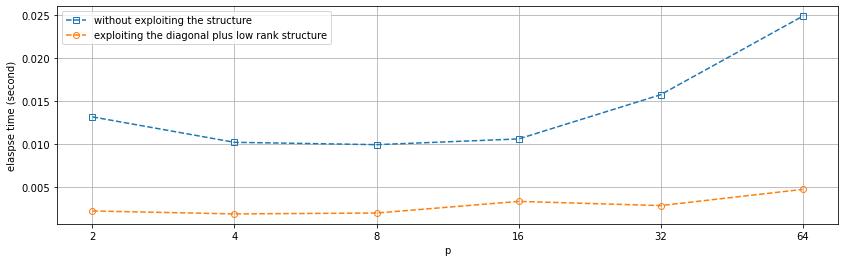

In [11]:
if __name__ == "__main__":
    run_profiling(n=100, m_s=[2, 4, 8, 16, 32, 64], n_dial=10)